In [ ]:
"""
Fast CAUSAL NUCLEUS (Monte-Carlo) on yield_preprocessed.npz
- Forces MC nucleolus, samples a limited set of coalitions, batches predict_proba
- Robust LP solving with GLPK/HiGHS→ECOS→OSQP→SCS fallback + hard time/iter caps
- Per-instance time guard + safe proportional-γ fallback to prevent stalls
- Saves: causal_graph_yield.png, attribution_causal_nucleus_yield.png, attribution_scores_yield_nucleus.csv
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx
import cvxpy as cp
from causallearn.search.ConstraintBased.PC import pc

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB=False

CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5,
    'NUC_EXACT_MAX_N': 12,
    'NUC_MC_COAL': 400,
}

FAST_CONFIG = {
    'FORCE_MC': True,         # never enumerate all coalitions
    'M_RESAMPLES': 24,        # 64 -> 24
    'GLOBAL_K': 20,           # 30 -> 20
    'N_DAGS': 3,              # 5 -> 3
    'NUC_MC_COAL': 120,       # 400 -> 120 coalitions per instance
    'BATCH_PRED': 256,        # batch size for predict_proba
    'SOLVERS': ("GLPK", "HiGHS", "ECOS", "OSQP", "SCS"),
    'OSQP_OPTS': {'max_iter': 20000, 'time_limit': 5.0},
    'SCS_OPTS':  {'max_iters': 5000},
    'ECOS_OPTS': {'max_iters': 500},
    'INSTANCE_BUDGET_SEC': 10.0,  # hard per-instance walltime
}

CONFIG.update({
    'M_RESAMPLES': FAST_CONFIG['M_RESAMPLES'],
    'GLOBAL_K': FAST_CONFIG['GLOBAL_K'],
    'N_DAGS': FAST_CONFIG['N_DAGS'],
    'NUC_MC_COAL': FAST_CONFIG['NUC_MC_COAL'],
})

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names
        n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            # orient undirected
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG equivalence class")
        return dags


class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new


class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total causal effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")
            # weights on edges X->X
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)
            # weights into Y
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))
            # path products
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                valid = False; break
                            prod *= ed["weight"]
                        if valid:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed over sampled DAGs")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalNucleus:
    def __init__(self, model, cstruct, X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.cstruct = cstruct
        self.features = list(X_train.columns)

        print("\nFitting SEMs & sampling DAGs for Causal Nucleus (FAST) ...")
        self.dags = self.cstruct.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()

        self._Ef_cache = None
        self.X_train = X_train
        print("Causal Nucleus ready")

    def _Ef(self, cls: int) -> float:
        if self._Ef_cache is None:
            P = self.model.predict_proba(self.X_train.values)
            self._Ef_cache = P.mean(axis=0)
        return float(self._Ef_cache[cls])

    def _batched_predict(self, rows: List[Dict[str, float]]) -> np.ndarray:
        if not rows:
            return np.zeros((0, len(np.unique(self.model.predict(self.X_train.values)))), dtype=float)
        X = pd.DataFrame(rows, columns=self.features).values
        out = []
        B = FAST_CONFIG['BATCH_PRED']
        for s in range(0, X.shape[0], B):
            out.append(self.model.predict_proba(X[s:s+B]))
        return np.vstack(out)

    def _vc_batched(self, S: Set[str], x_row: pd.Series, cls: int, M: int) -> float:
        per = max(1, M // max(1, len(self.sems)))
        batch_rows = []
        for sem in self.sems:
            for _ in range(per):
                batch_rows.append(sem.sample_intervention(S, x_row))
        P = self._batched_predict(batch_rows)
        return float(P[:, cls].mean()) if len(P) else 0.0

    def _build_mc_game(self, x_row: pd.Series, cls: int, M: int):
        names = self.features
        gamma = self.gamma
        Gsum = sum(abs(gamma[k]) for k in names) + 1e-12
        Ef = self._Ef(cls)

        n = len(names)
        idx = list(range(n))
        rng_local = np.random.default_rng(CONFIG['RANDOM_SEED'])

        coalitions = []
        coalitions.append(idx[:])           # grand coalition
        for i in idx:
            coalitions.append([i])          # singletons
        while len(coalitions) < CONFIG['NUC_MC_COAL']:
            size = int(rng_local.integers(1, n))
            S = sorted(rng_local.choice(idx, size=size, replace=False).tolist())
            if S not in coalitions:
                coalitions.append(S)

        A = np.zeros((len(coalitions), n), dtype=float)
        v = np.zeros((len(coalitions),), dtype=float)
        for i, Sidx in enumerate(coalitions):
            Sset = {names[j] for j in Sidx}
            vcS = self._vc_batched(Sset, x_row, cls, M)
            gS = sum(abs(gamma[nm]) for nm in Sset)
            A[i, Sidx] = 1.0
            v[i] = (vcS - Ef) * (gS / Gsum)
        return A, v

    def _solve_nucleolus_mc(self, A: np.ndarray, v: np.ndarray) -> np.ndarray:
        n = A.shape[1]
        gidx = int(np.argmax(A.sum(axis=1)))
        x = cp.Variable(n)
        e = cp.Variable()
        constraints = [cp.sum(x) == v[gidx]]
        active = [i for i in range(A.shape[0]) if i != gidx]

        def _solve_once(round_constraints) -> bool:
            for _solver in FAST_CONFIG['SOLVERS']:
                opts = {}
                if _solver == "OSQP":  opts = FAST_CONFIG.get('OSQP_OPTS', {})
                if _solver == "SCS":   opts = FAST_CONFIG.get('SCS_OPTS',  {})
                if _solver == "ECOS":  opts = FAST_CONFIG.get('ECOS_OPTS', {})
                try:
                    prob = cp.Problem(cp.Minimize(e), round_constraints)
                    prob.solve(solver=_solver, verbose=False, **opts)
                    if x.value is not None and e.value is not None and prob.status in ("optimal", "optimal_inaccurate"):
                        return True
                except Exception:
                    continue
            return False

        for _ in range(3 * n):
            round_constraints = constraints + [v[i] - A[i] @ x <= e for i in active]
            if not _solve_once(round_constraints):
                # proportional-to-γ allocation summing to v(grand)
                gamma = self.gamma
                names = self.features
                gsum = sum(abs(gamma[k]) for k in names) + 1e-12
                total = float(v[gidx])
                if gsum == 0:
                    return np.zeros(n, dtype=float)
                return np.array([total * abs(gamma[nm]) / gsum for nm in names], dtype=float)

            xval = x.value
            eval_ = float(e.value)
            newly = []
            for i in active:
                ex_i = float(v[i] - A[i] @ xval)
                if abs(ex_i - eval_) <= 1e-5:
                    newly.append(i)
            if not newly:
                break
            for i in newly:
                constraints.append(v[i] - A[i] @ x == eval_)
            active = [i for i in active if i not in newly]
            if not active:
                break

        return np.array(x.value if x.value is not None else np.zeros(n), dtype=float)

    def _instance_nucleolus(self, x_row: pd.Series, M: int = None) -> np.ndarray:
        if M is None:
            M = CONFIG['M_RESAMPLES']
        probs = self.model.predict_proba(pd.DataFrame([x_row], columns=self.features).values)[0]
        cls = int(np.argmax(probs))
        A, v = self._build_mc_game(x_row, cls, M)
        return self._solve_nucleolus_mc(A, v)

    def _quick_gamma_fallback(self, x_row: pd.Series) -> np.ndarray:
        # compute quick total surplus ~ (vc(N) - Ef) with tiny M, then distribute by |γ|
        probs = self.model.predict_proba(pd.DataFrame([x_row], columns=self.features).values)[0]
        cls = int(np.argmax(probs))
        Ef = self._Ef(cls)
        tiny_M = max(4, CONFIG['M_RESAMPLES'] // 4)
        vcN = self._vc_batched(set(self.features), x_row, cls, tiny_M)
        total = float(vcN - Ef)
        gamma = self.gamma
        gsum = sum(abs(gamma[k]) for k in self.features) + 1e-12
        if gsum == 0:
            return np.zeros(len(self.features), dtype=float)
        return np.array([total * abs(gamma[nm]) / gsum for nm in self.features], dtype=float)

    def explain_global(self, X_test: pd.DataFrame, k: int = None) -> pd.Series:
        if k is None:
            k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal Nucleus (FAST MC) over {k} instances ...")

        import time
        t0 = time.perf_counter()
        vals = []
        for t, i in enumerate(idx, 1):
            t_i = time.perf_counter()
            alloc = None
            try:
                alloc = self._instance_nucleolus(X_test.iloc[i])
            except Exception:
                alloc = None
            # If instance took too long or failed, use quick γ-fallback
            if alloc is None or (time.perf_counter() - t_i) > FAST_CONFIG['INSTANCE_BUDGET_SEC']:
                alloc = self._quick_gamma_fallback(X_test.iloc[i])
            vals.append(alloc)
            if t % 5 == 0 or t == k:
                elapsed = time.perf_counter() - t0
                print(f"  {t}/{k}  elapsed={elapsed:.1f}s  ~{elapsed/max(1,t):.2f}s/inst")

        mean_alloc = np.mean(np.vstack(vals), axis=0)
        return pd.Series(mean_alloc, index=self.features, name="Causal_Nucleus")


def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def plot_nucleus_bar(series: pd.Series, title="Causal Nucleus (global) — Yield NPZ"):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(np.arange(len(series)), series.values)
    ax.set_xticks(np.arange(len(series))); ax.set_xticklabels(series.index, rotation=45, ha='right')
    ax.set_ylabel('Allocation'); ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    return fig


def main():
    print("\n" + "="*72)
    print("CAUSAL NUCLEUS (FAST MC, robust) on NPZ")
    print("="*72 + "\n")

    print("Loading NPZ ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys()); print(f"keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found."); return

    need = {'X_train','X_test','y_train','y_test','feature_names'}
    if not need.issubset(set(keys)):
        print("ERROR: NPZ must include X_train, X_test, y_train, y_test, feature_names"); return

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = int(len(np.unique(y_train))); print(f"Target classes: {n_classes}")

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    print("\n" + "="*72); print("Training model"); print("="*72)
    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160, max_depth=5, learning_rate=0.08,
            subsample=0.9, colsample_bytree=0.9, random_state=CONFIG['RANDOM_SEED'],
            verbosity=0, objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
        print("Using Random Forest")
    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test,y_pred):.4f}  MacroF1={f1_score(y_test,y_pred,average='macro'): .4f}")

    print("\n" + "="*72); print("Step 1: Causal discovery (PC)"); print("="*72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel)
    fig.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Saved 'causal_graph_yield.png'")

    print("\n" + "="*72); print("Step 2: Causal Nucleus (FAST MC)"); print("="*72)
    cnuc = CausalNucleus(model, cs, Xtr, y_train)
    nuc_glob = cnuc.explain_global(Xte, k=CONFIG['GLOBAL_K'])

    print("\n" + "="*72); print("Step 3: Save & Plot"); print("="*72)
    df = pd.DataFrame({"Causal_Nucleus": nuc_glob})
    df.to_csv("attribution_scores_yield_nucleus.csv", index=True)
    print(df.round(6).to_string())
    print("\nSaved: attribution_scores_yield_nucleus.csv")

    fig2 = plot_nucleus_bar(nuc_glob, title="Causal Nucleus (global) — Yield NPZ")
    fig2.savefig('attribution_causal_nucleus_yield.png', dpi=150, bbox_inches='tight')
    print("Saved 'attribution_causal_nucleus_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()


CAUSAL NUCLEUS (FAST MC, robust) on NPZ

Loading NPZ ...
✓ keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3

Training model
Using Random Forest
✓ Accuracy=0.8250  MacroF1= 0.8280

Step 1: Causal discovery (PC)
Running PC algorithm on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 4 edges
✓ Saved 'causal_graph_yield.png'

Step 2: Causal Nucleus (FAST MC)

Fitting SEMs & sampling DAGs for Causal Nucleus (FAST) ...
✓ Sampled 3 DAG(s) from CPDAG equivalence class
Computing IDA-style total causal effects W_i ...
✓ W_i computed over sampled DAGs
✓ Causal Nucleus ready

Computing global Causal Nucleus (FAST MC) over 20 instances ...


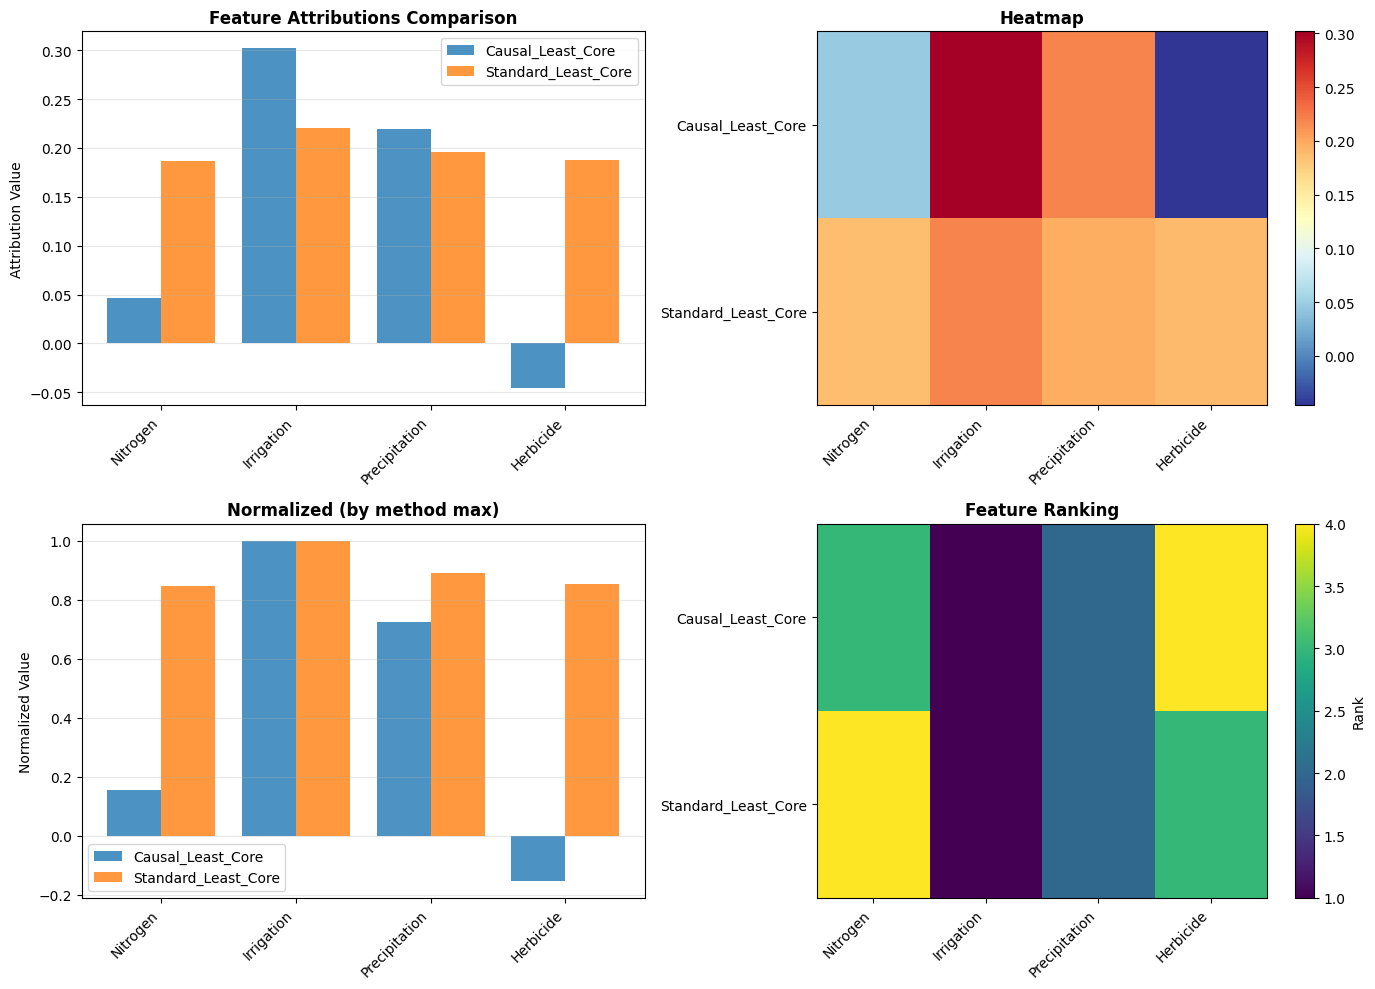

In [4]:
"""
CAUSAL LEAST CORE on yield_preprocessed.npz
Integrates causal structure discovery with least core computation for fair attribution.

Key innovations:
1. Causal value function: v(S) uses interventional distributions P(X_{-S} | do(X_S))
2. Causal constraints: Respects causal ordering when forming coalitions
3. Gamma-weighted utilities: Incorporates total causal effects W_i
4. Monte Carlo approximation for scalability

Saves: causal_least_core_results.csv, comparison_plots.png
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set, Callable
import cvxpy as cp
from itertools import combinations, chain
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB=False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'M_RESAMPLES': 32,        # samples for interventional distribution
    'N_DAGS': 3,              # DAGs sampled from CPDAG
    'MC_ITERATIONS': 500,     # Monte Carlo coalitions for least core
    'EPSILON': 0.01,          # slack for approximate core
    'RANDOM_SEED': 42,
    'USE_CAUSAL_CONSTRAINTS': True,  # respect causal ordering
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


class CausalStructure:
    """PC discovery → CPDAG → sample DAGs."""
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed")
        return self

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """Sample DAGs by orienting undirected edges; ensure acyclicity."""
        dags = []
        names = self.feature_names
        n = len(names)

        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags


class LinearMechanisms:
    """SEM fitting for interventional sampling."""
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """Sample from P(X_{-S} | do(X_S = x_S))."""
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new


class CausalEffects:
    """Compute W_i via path products; average over DAGs."""
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing total causal effects W_i...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12: G.add_edge(u, v, weight=w)

            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12: G.add_edge(feat, "Y", weight=float(w))

            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed: valid = False; break
                            prod *= ed["weight"]
                        if valid: total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalLeastCore:
    """
    Least core with causal value function:
    v(S) = E_{X_{-S} ~ P(·|do(X_S))} [f(X)]

    Uses Monte Carlo sampling of coalitions and interventional distributions.
    """
    def __init__(self, model, structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = structure
        self.X_train = X_train
        self.y_train = y_train
        self.features = list(X_train.columns)
        self.n = len(self.features)

        print("\nFitting SEMs & sampling DAGs for Causal Least Core...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()

        print("Causal Least Core ready")

    def causal_value(self, S: Set[int], x: pd.Series, M: int = None) -> float:
        """
        Causal value function for coalition S (indices).
        Returns average prediction under intervention do(X_S = x_S).
        """
        if M is None: M = CONFIG['M_RESAMPLES']

        S_names = {self.features[i] for i in S}
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))

        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S_names, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                # Use max probability as value
                probs = self.model.predict_proba(X_mat)[0]
                total += float(np.max(probs))

        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def is_valid_coalition(self, S: Set[int]) -> bool:
        """
        Check if coalition respects causal constraints.
        If USE_CAUSAL_CONSTRAINTS=True, only allow coalitions where
        if i in S and j is a descendant of i, then j in S.
        """
        if not CONFIG['USE_CAUSAL_CONSTRAINTS']:
            return True

        # Use first DAG for constraint checking
        dag = self.dags[0] if self.dags else nx.DiGraph()
        S_names = {self.features[i] for i in S}

        for i in S:
            feat = self.features[i]
            try:
                descendants = nx.descendants(dag, feat)
                for desc in descendants:
                    if desc in self.features:
                        desc_idx = self.features.index(desc)
                        if desc_idx not in S:
                            return False
            except Exception:
                pass
        return True

    def sample_coalitions(self, n_samples: int, x: pd.Series) -> Tuple[np.ndarray, np.ndarray]:
        """
        Sample random coalitions and compute their causal values.
        Returns (constraints, utility_values) for LP.
        """
        constraints = []
        utility_values = []

        print(f"Sampling {n_samples} coalitions...")
        for i in range(n_samples):
            if i % 100 == 0:
                print(f"  {i}/{n_samples}")

            # Sample coalition size (avoid empty and full)
            size = np.random.randint(1, self.n)

            # Try to sample valid coalition
            for _ in range(10):  # max retries
                S = set(np.random.choice(self.n, size, replace=False))
                if self.is_valid_coalition(S):
                    break

            # Compute causal value
            val = self.causal_value(S, x)

            # Weight by gamma (causal importance)
            gamma_weight = sum(self.gamma[self.features[j]] for j in S) / len(S) if S else 1.0
            val *= gamma_weight

            utility_values.append(val)
            constraint = np.zeros(self.n)
            constraint[list(S)] = 1
            constraints.append(constraint)

        return np.array(constraints), np.array(utility_values)

    def compute_least_core(self, x: pd.Series, n_iterations: int = None,
                          epsilon: float = None) -> Dict:
        """
        Solve causal least core LP for instance x.

        minimize e (subsidy)
        s.t. sum(phi_i) = v(N)
             sum_{i in S} phi_i + e >= v(S) - epsilon  for all S
        """
        if n_iterations is None: n_iterations = CONFIG['MC_ITERATIONS']
        if epsilon is None: epsilon = CONFIG['EPSILON']

        # Grand coalition value
        v_N = self.causal_value(set(range(self.n)), x)

        # Sample coalitions
        A_lb, b_lb = self.sample_coalitions(n_iterations, x)

        # Solve LP
        phi = cp.Variable(self.n)
        e = cp.Variable()

        objective = cp.Minimize(e)
        constraints = [
            cp.sum(phi) == v_N,
            A_lb @ phi + e >= b_lb - epsilon
        ]

        problem = cp.Problem(objective, constraints)
        problem.solve(verbose=False)

        if problem.status not in ["optimal", "optimal_inaccurate"]:
            print(f"Warning: LP status = {problem.status}")
            return {
                "values": np.zeros(self.n),
                "subsidy": float('inf'),
                "status": problem.status
            }

        return {
            "values": phi.value,
            "subsidy": e.value,
            "status": problem.status,
            "v_N": v_N
        }

    def compute_global(self, X_test: pd.DataFrame, k: int = 10) -> pd.DataFrame:
        """Compute causal least core for k test instances and average."""
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)

        print(f"\nComputing global Causal Least Core over {k} instances...")
        results = []

        for t, i in enumerate(idx, 1):
            if t % 5 == 0:
                print(f"  {t}/{k}")
            res = self.compute_least_core(X_test.iloc[i])
            results.append(res['values'])

        avg_values = np.mean(results, axis=0)
        return pd.Series(avg_values, index=self.features, name="Causal_Least_Core")


def compute_standard_least_core(model, X_train, X_test, k=20):
    """Standard least core with model-based utility v(S) = E[f(X_S, X_{-S})]."""
    print("\nComputing Standard Least Core (baseline)...")

    def standard_utility(S: Set[int], x: pd.Series, X_bg: pd.DataFrame, M: int = 32) -> float:
        """Sample from marginal P(X_{-S}) instead of interventional."""
        features = list(X_bg.columns)
        S_names = {features[i] for i in S}

        total = 0.0
        for _ in range(M):
            x_new = x.copy()
            # Sample non-coalition features from background
            for i, feat in enumerate(features):
                if i not in S:
                    x_new[feat] = X_bg[feat].sample(1).iloc[0]
            probs = model.predict_proba(pd.DataFrame([x_new], columns=features).values)[0]
            total += float(np.max(probs))
        return total / M

    n = len(X_train.columns)
    idx = rng.choice(len(X_test), size=min(k, len(X_test)), replace=False)
    results = []

    for t, i in enumerate(idx, 1):
        if t % 5 == 0:
            print(f"  {t}/{len(idx)}")

        x = X_test.iloc[i]
        v_N = standard_utility(set(range(n)), x, X_train)

        # Sample coalitions
        constraints = []
        utility_values = []
        for _ in range(CONFIG['MC_ITERATIONS']):
            size = np.random.randint(1, n)
            S = set(np.random.choice(n, size, replace=False))
            val = standard_utility(S, x, X_train, M=16)
            utility_values.append(val)
            constraint = np.zeros(n)
            constraint[list(S)] = 1
            constraints.append(constraint)

        A_lb = np.array(constraints)
        b_lb = np.array(utility_values)

        # Solve LP
        phi = cp.Variable(n)
        e = cp.Variable()
        objective = cp.Minimize(e)
        constraints_cvx = [
            cp.sum(phi) == v_N,
            A_lb @ phi + e >= b_lb - CONFIG['EPSILON']
        ]
        problem = cp.Problem(objective, constraints_cvx)
        problem.solve(verbose=False)

        if problem.status in ["optimal", "optimal_inaccurate"]:
            results.append(phi.value)

    avg_values = np.mean(results, axis=0)
    return pd.Series(avg_values, index=X_train.columns, name="Standard_Least_Core")


def plot_comparison(df: pd.DataFrame):
    """Compare different attribution methods."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    x_pos = np.arange(len(df.index))
    width = 0.8 / len(df.columns)
    for i, col in enumerate(df.columns):
        axes[0, 0].bar(x_pos + i*width, df[col], width, label=col, alpha=0.8)
    axes[0, 0].set_xticks(x_pos + width*(len(df.columns)-1)/2)
    axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution Value')
    axes[0, 0].set_title('Feature Attributions Comparison', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    im = axes[0, 1].imshow(df.T.values, aspect='auto', cmap='RdYlBu_r')
    axes[0, 1].set_xticks(np.arange(len(df.index)))
    axes[0, 1].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 1].set_yticks(np.arange(len(df.columns)))
    axes[0, 1].set_yticklabels(df.columns)
    axes[0, 1].set_title('Heatmap', fontweight='bold')
    plt.colorbar(im, ax=axes[0, 1])

    # Normalized comparison
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(x_pos + i*width, df_norm[col], width, label=col, alpha=0.8)
    axes[1, 0].set_xticks(x_pos + width*(len(df_norm.columns)-1)/2)
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].set_ylabel('Normalized Value')
    axes[1, 0].set_title('Normalized (by method max)', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Ranking
    ranks = df.rank(ascending=False)
    im2 = axes[1, 1].imshow(ranks.T.values, aspect='auto', cmap='viridis')
    axes[1, 1].set_xticks(np.arange(len(ranks.index)))
    axes[1, 1].set_xticklabels(ranks.index, rotation=45, ha='right')
    axes[1, 1].set_yticks(np.arange(len(ranks.columns)))
    axes[1, 1].set_yticklabels(ranks.columns)
    axes[1, 1].set_title('Feature Ranking', fontweight='bold')
    plt.colorbar(im2, ax=axes[1, 1], label='Rank')

    fig.tight_layout()
    return fig


def main():
    print("\n" + "="*72)
    print("CAUSAL LEAST CORE")
    print("="*72 + "\n")

    # Load data
    print("Loading NPZ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        print(f"keys: {list(data.keys())}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found.")
        return

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test = pd.DataFrame(data['X_test'], columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")

    # Scale
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    # Train model
    print("\n" + "="*72)
    print("Training model")
    print("="*72)
    n_classes = len(np.unique(y_train))

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=100, max_depth=5, learning_rate=0.1,
            random_state=CONFIG['RANDOM_SEED'], verbosity=0,
            objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(
            n_estimators=100, max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest")

    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test, y_pred):.4f}")

    # Causal discovery
    print("\n" + "="*72)
    print("Causal Discovery (PC)")
    print("="*72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)

    # Causal Least Core
    print("\n" + "="*72)
    print("Computing Causal Least Core")
    print("="*72)
    clc = CausalLeastCore(model, cs, Xtr, y_train)

    print("\nCausal effects (gamma weights):")
    for f in Xtr.columns:
        print(f"  {f:15s}  γ={clc.gamma[f]:.5f}")

    causal_lc = clc.compute_global(Xte, k=20)

    # Baseline
    standard_lc = compute_standard_least_core(model, Xtr, Xte, k=10)

    # Comparison
    print("\n" + "="*72)
    print("Results")
    print("="*72)
    df = pd.DataFrame({
        "Causal_Least_Core": causal_lc,
        "Standard_Least_Core": standard_lc
    })

    df.to_csv("causal_least_core_results.csv", index=True)
    print(df.round(6).to_string())
    print("\nSaved: causal_least_core_results.csv")

    # Plot
    fig = plot_comparison(df)
    fig.savefig('comparison_plots.png', dpi=150, bbox_inches='tight')
    print("Saved: comparison_plots.png")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()


CAUSAL SHAPLEY–SHUBIK

Loading NPZ...
✓ keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide

Training model
Using Random Forest
✓ Accuracy=0.8350  MacroF1= 0.8386

Causal Discovery (PC)
Running PC on 4 features...
✓ PC completed

Computing Causal Shapley–Shubik

Fitting SEMs & sampling DAGs for Causal Shapley–Shubik...
✓ Sampled 3 DAG(s)
Computing total causal effects W_i...
✓ W_i computed
✓ Causal Shapley–Shubik ready

Causal effects (gamma weights):
  Nitrogen         γ=0.20963
  Irrigation       γ=0.44137
  Precipitation    γ=0.25886
  Herbicide        γ=0.09014

Computing global Causal Shapley–Shubik (Monte Carlo) over 10 instances...
  Instance 3/10
  Instance 6/10
  Instance 9/10

Computing global Causal Shapley–Shubik (Exact) over 10 instances...
  Instance 3/10
  Instance 6/10
  Instance 9/10

Computing Standard Shapley–Shubik (baseline, MC)...
  Instance 3/10
  Ins

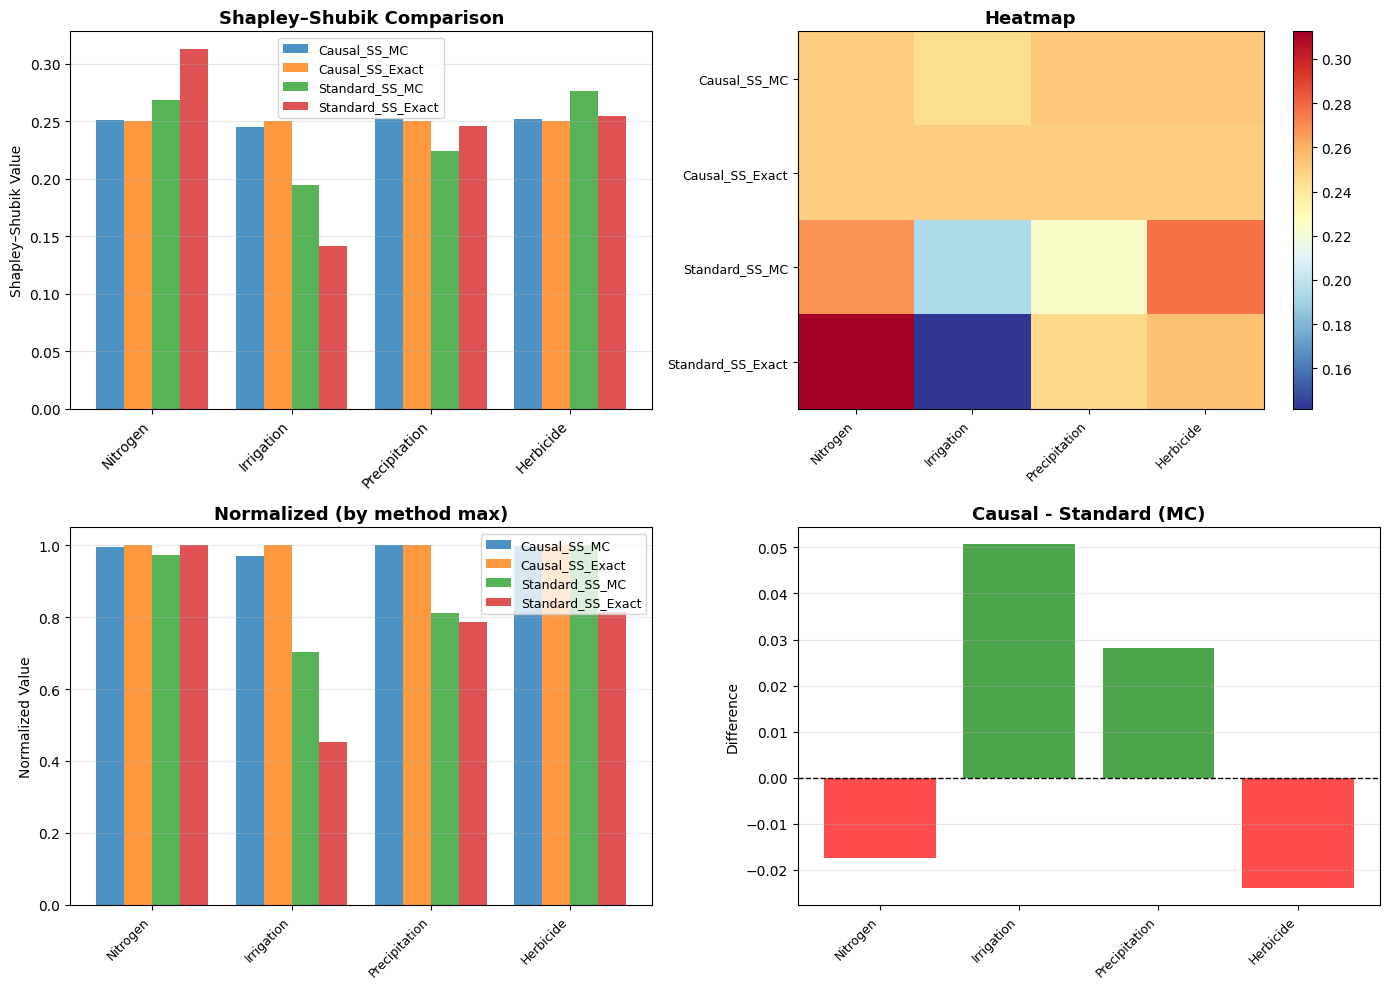

In [6]:
"""
CAUSAL SHAPLEY–SHUBIK on yield_preprocessed.npz

Extends the Shapley–Shubik index to incorporate causal structure:
- Uses interventional value function v(S) = E[f(X) | do(X_S)]
- Optionally weights coalition values by causal effects (gamma_i)
- Uses exact permutations or Monte Carlo permutations per instance

Shapley–Shubik index:
    φ_i = P(i is pivotal in a random permutation)

Here, "pivotal" means the first player in the permutation whose addition
strictly increases v(S).

Causal version:
    - v(S) uses interventional distributions via SEM & DAG ensemble
    - Optionally multiplies v(S) by average γ_i over i ∈ S

Saves: causal_shapley_shubik_results.csv, shapley_shubik_comparison.png
"""

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False
HAVE_XGB=False

from causallearn.search.ConstraintBased.PC import pc


CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'M_RESAMPLES': 48,         # samples for interventional distribution
    'N_DAGS': 3,               # DAGs sampled from CPDAG
    'MC_PERMS': 2000,          # Monte Carlo permutations per instance
    'RANDOM_SEED': 42,
    'K_INSTANCES': 10,         # instances for global averaging
    'USE_GAMMA_WEIGHTS': True, # weight v(S) by causal γ_i
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


class CausalStructure:
    """PC discovery → CPDAG → sample DAGs."""
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed")
        return self

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """Sample DAGs by orienting undirected edges; ensure acyclicity."""
        dags = []
        names = self.feature_names
        n = len(names)

        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            # orient undirected edges
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            # last guard
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags


class LinearMechanisms:
    """SEM fitting for interventional sampling."""
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """Sample from P(X_{-S} | do(X_S = x_S))."""
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new


class CausalEffects:
    """Compute W_i via path products; average over DAGs."""
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing total causal effects W_i...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12: G.add_edge(u, v, weight=w)

            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12: G.add_edge(feat, "Y", weight=float(w))

            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed: valid = False; break
                            prod *= ed["weight"]
                        if valid: total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        """Normalized causal importance weights."""
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalShapleyShubik:
    """
    Causal Shapley–Shubik index.

    Standard Shapley–Shubik:
        φ_i = P(i is pivotal in a random permutation)

    Here, v(S) is defined via interventional expectations:
        v(S) = E[f(X) | do(X_S = x_S)]
    and "pivotal" is the first feature in the permutation such that
        v(S ∪ {i}) > v(S).

    Causal version:
        - v(S) via SEMs over sampled DAGs
        - Optionally multiply v(S) by average γ_i over i ∈ S
    """
    def __init__(self, model, structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = structure
        self.X_train = X_train
        self.y_train = y_train
        self.features = list(X_train.columns)
        self.n = len(self.features)

        print("\nFitting SEMs & sampling DAGs for Causal Shapley–Shubik...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()

        print("Causal Shapley–Shubik ready")

    def causal_value(self, S: Set[int], x: pd.Series, M: int = None) -> float:
        """
        Causal value function for coalition S (indices).
        Value = average max class probability under do(X_S = x_S).
        """
        if M is None: M = CONFIG['M_RESAMPLES']
        if not S:
            return 0.0

        S_names = {self.features[i] for i in S}
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))

        # Batch all samples for speed
        all_samples = []
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S_names, x)
                all_samples.append([x_sample[f] for f in self.features])

        X_mat = np.array(all_samples)
        probs = self.model.predict_proba(X_mat)
        value = float(np.max(probs, axis=1).mean())

        if CONFIG['USE_GAMMA_WEIGHTS']:
            gamma_avg = np.mean([self.gamma[self.features[i]] for i in S])
            value *= float(gamma_avg)

        return value


    def _exact_ss_instance(self, x: pd.Series) -> np.ndarray:
        """
        Exact Shapley–Shubik for a single instance x.
        """
        players = list(range(self.n))
        scores = np.zeros(self.n, dtype=float)
        total_perms = math.factorial(self.n)

        for perm in itertools.permutations(players):
            S = set()
            prev_val = self.causal_value(S, x)
            for p in perm:
                S_next = S | {p}
                cur_val = self.causal_value(S_next, x)
                if cur_val > prev_val:
                    scores[p] += 1.0
                    break
                S = S_next
                prev_val = cur_val

        scores /= total_perms
        return scores

    def _mc_ss_instance(self, x: pd.Series, n_perms: int) -> np.ndarray:
        """
        Monte Carlo Shapley–Shubik for a single instance x.
        """
        players = np.arange(self.n)
        scores = np.zeros(self.n, dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(players)
            S = set()
            prev_val = self.causal_value(S, x)
            for p in perm:
                S_next = S | {int(p)}
                cur_val = self.causal_value(S_next, x)
                if cur_val > prev_val:
                    scores[int(p)] += 1.0
                    break
                S = S_next
                prev_val = cur_val

        scores /= n_perms
        return scores

    def compute_global(self, X_test: pd.DataFrame, k: int = None,
                       use_mc: bool = True) -> pd.Series:
        """Compute global causal Shapley–Shubik over k test instances."""
        import itertools as _it  # local to avoid confusion with global

        global itertools
        itertools = _it  # ensure permutations is available inside methods

        if k is None:
            k = CONFIG['K_INSTANCES']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)

        method = "Monte Carlo" if use_mc else "Exact"
        print(f"\nComputing global Causal Shapley–Shubik ({method}) over {k} instances...")

        results = []
        for t, i in enumerate(idx, 1):
            if t % 3 == 0:
                print(f"  Instance {t}/{k}")
            x = X_test.iloc[i]
            if use_mc:
                res = self._mc_ss_instance(x, n_perms=CONFIG['MC_PERMS'])
            else:
                res = self._exact_ss_instance(x)
            results.append(res)

        avg_values = np.mean(results, axis=0)
        label = f"Causal_SS_{'MC' if use_mc else 'Exact'}"
        return pd.Series(avg_values, index=self.features, name=label)


def compute_standard_shapley_shubik(model, X_train, X_test,
                                    k=10, use_mc=True) -> pd.Series:
    """
    Standard Shapley–Shubik index without causal structure.
    Utility uses marginal sampling P(X_{-S}).
    """
    import itertools as _it
    global itertools
    itertools = _it

    print(f"\nComputing Standard Shapley–Shubik (baseline, {'MC' if use_mc else 'Exact'})...")

    def standard_utility(S: Set[int], x: pd.Series, X_bg: pd.DataFrame, M: int = 32) -> float:
        features = list(X_bg.columns)
        total = 0.0
        for _ in range(M):
            x_new = x.copy()
            for j, feat in enumerate(features):
                if j not in S:
                    x_new[feat] = X_bg[feat].sample(1).iloc[0]
            probs = model.predict_proba(pd.DataFrame([x_new], columns=features).values)[0]
            total += float(np.max(probs))
        return total / M

    n = len(X_train.columns)
    idx = rng.choice(len(X_test), size=min(k, len(X_test)), replace=False)
    results = []

    for t, i in enumerate(idx, 1):
        if t % 3 == 0:
            print(f"  Instance {t}/{len(idx)}")
        x = X_test.iloc[i]
        players = list(range(n))
        scores = np.zeros(n, dtype=float)

        if use_mc:
            # Monte Carlo permutations
            for _ in range(CONFIG['MC_PERMS']):
                perm = rng.permutation(players)
                S = set()
                prev_val = standard_utility(S, x, X_train, M=16)
                for p in perm:
                    S_next = S | {int(p)}
                    cur_val = standard_utility(S_next, x, X_train, M=16)
                    if cur_val > prev_val:
                        scores[int(p)] += 1.0
                        break
                    S = S_next
                    prev_val = cur_val
            scores /= CONFIG['MC_PERMS']
        else:
            # Exact permutations (only safe for small n)
            total_perms = math.factorial(n)
            for perm in itertools.permutations(players):
                S = set()
                prev_val = standard_utility(S, x, X_train, M=24)
                for p in perm:
                    S_next = S | {p}
                    cur_val = standard_utility(S_next, x, X_train, M=24)
                    if cur_val > prev_val:
                        scores[p] += 1.0
                        break
                    S = S_next
                    prev_val = cur_val
            scores /= total_perms

        results.append(scores)

    avg_values = np.mean(results, axis=0)
    label = f"Standard_SS_{'MC' if use_mc else 'Exact'}"
    return pd.Series(avg_values, index=X_train.columns, name=label)


def plot_comparison(df: pd.DataFrame):
    """Compare different Shapley–Shubik methods."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    x_pos = np.arange(len(df.index))
    width = 0.8 / len(df.columns)

    # Bar plot
    for i, col in enumerate(df.columns):
        axes[0, 0].bar(x_pos + i*width, df[col], width, label=col, alpha=0.8)
    axes[0, 0].set_xticks(x_pos + width*(len(df.columns)-1)/2)
    axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Shapley–Shubik Value')
    axes[0, 0].set_title('Shapley–Shubik Comparison', fontweight='bold', fontsize=13)
    axes[0, 0].legend(fontsize=9)
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    im = axes[0, 1].imshow(df.T.values, aspect='auto', cmap='RdYlBu_r')
    axes[0, 1].set_xticks(np.arange(len(df.index)))
    axes[0, 1].set_xticklabels(df.index, rotation=45, ha='right', fontsize=9)
    axes[0, 1].set_yticks(np.arange(len(df.columns)))
    axes[0, 1].set_yticklabels(df.columns, fontsize=9)
    axes[0, 1].set_title('Heatmap', fontweight='bold', fontsize=13)
    plt.colorbar(im, ax=axes[0, 1])

    # Normalized comparison
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(x_pos + i*width, df_norm[col], width, label=col, alpha=0.8)
    axes[1, 0].set_xticks(x_pos + width*(len(df_norm.columns)-1)/2)
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right', fontsize=9)
    axes[1, 0].set_ylabel('Normalized Value')
    axes[1, 0].set_title('Normalized (by method max)', fontweight='bold', fontsize=13)
    axes[1, 0].legend(fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Difference Causal - Standard (MC)
    if 'Standard_SS_MC' in df.columns and 'Causal_SS_MC' in df.columns:
        diff = df['Causal_SS_MC'] - df['Standard_SS_MC']
        colors = ['green' if v > 0 else 'red' for v in diff]
        axes[1, 1].bar(x_pos, diff, color=colors, alpha=0.7)
        axes[1, 1].set_xticks(x_pos)
        axes[1, 1].set_xticklabels(df.index, rotation=45, ha='right', fontsize=9)
        axes[1, 1].set_ylabel('Difference')
        axes[1, 1].set_title('Causal - Standard (MC)', fontweight='bold', fontsize=13)
        axes[1, 1].axhline(y=0, color='black', linestyle='--', linewidth=1)
        axes[1, 1].grid(axis='y', alpha=0.3)
    else:
        axes[1, 1].text(0.5, 0.5, 'Difference plot\nrequires both MC methods',
                        ha='center', va='center', transform=axes[1, 1].transAxes)

    fig.tight_layout()
    return fig


def main():
    print("\n" + "="*72)
    print("CAUSAL SHAPLEY–SHUBIK")
    print("="*72 + "\n")

    # Load data
    print("Loading NPZ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        print(f"keys: {list(data.keys())}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found.")
        return

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")

    # Scale
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    # Train model
    print("\n" + "="*72)
    print("Training model")
    print("="*72)
    n_classes = len(np.unique(y_train))

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=100, max_depth=5, learning_rate=0.1,
            random_state=CONFIG['RANDOM_SEED'], verbosity=0,
            objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(
            n_estimators=100, max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest")

    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test, y_pred):.4f}  "
          f"MacroF1={f1_score(y_test, y_pred, average='macro'): .4f}")

    # Causal discovery
    print("\n" + "="*72)
    print("Causal Discovery (PC)")
    print("="*72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)

    # Causal Shapley-Shubik
    print("\n" + "="*72)
    print("Computing Causal Shapley–Shubik")
    print("="*72)
    css = CausalShapleyShubik(model, cs, Xtr, y_train)

    print("\nCausal effects (gamma weights):")
    for f in Xtr.columns:
        print(f"  {f:15s}  γ={css.gamma[f]:.5f}")

    causal_ss_mc    = css.compute_global(Xte, k=CONFIG['K_INSTANCES'], use_mc=True)
    causal_ss_exact = css.compute_global(Xte, k=CONFIG['K_INSTANCES'], use_mc=False)

    # Baselines
    standard_ss_mc    = compute_standard_shapley_shubik(model, Xtr, Xte,
                                                        k=CONFIG['K_INSTANCES'], use_mc=True)
    standard_ss_exact = compute_standard_shapley_shubik(model, Xtr, Xte,
                                                        k=CONFIG['K_INSTANCES'], use_mc=False)

    # Results & plots
    print("\n" + "="*72)
    print("Results")
    print("="*72)
    df = pd.DataFrame({
        "Causal_SS_MC":        causal_ss_mc,
        "Causal_SS_Exact":     causal_ss_exact,
        "Standard_SS_MC":      standard_ss_mc,
        "Standard_SS_Exact":   standard_ss_exact,
    })

    df.to_csv("causal_shapley_shubik_results.csv", index=True)
    print(df.round(6).to_string())
    print("\nSaved: causal_shapley_shubik_results.csv")

    fig = plot_comparison(df)
    fig.savefig("shapley_shubik_comparison.png", dpi=150, bbox_inches='tight')
    print("Saved: shapley_shubik_comparison.png")

    try:
        plt.show()
    except Exception:
        pass


if __name__ == "__main__":
    main()


CAUSAL NUCLEOLUS

Loading NPZ...
✓ keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide

Training model
Using Random Forest
✓ Accuracy=0.8350  MacroF1= 0.8386

Causal Discovery (PC)
Running PC on 4 features...
✓ PC completed

Computing Causal Nucleolus

Fitting SEMs & sampling DAGs for Causal Nucleolus...
✓ Sampled 3 DAG(s)
Computing total causal effects W_i...
✓ W_i computed
✓ Causal Nucleolus ready

Causal effects (gamma weights):
  Nitrogen         γ=0.20963
  Irrigation       γ=0.44137
  Precipitation    γ=0.25886
  Herbicide        γ=0.09014

Computing global Causal Nucleolus over 10 instances...


  Instance 3/10


  Instance 6/10


  Instance 9/10



Computing Standard Nucleolus (baseline)...


  Instance 3/10


  Instance 6/10


  Instance 9/10



Results
               Causal_Nucleolus  Standard_Nucleolus
Nitrogen               0.014010            0.182763
Irrigation             0.161421            0.199392
Precipitation          0.041571            0.179036
Herbicide             -0.053651            0.170956

✓ Saved: causal_nucleolus_results.csv
✓ Saved: nucleolus_comparison.png


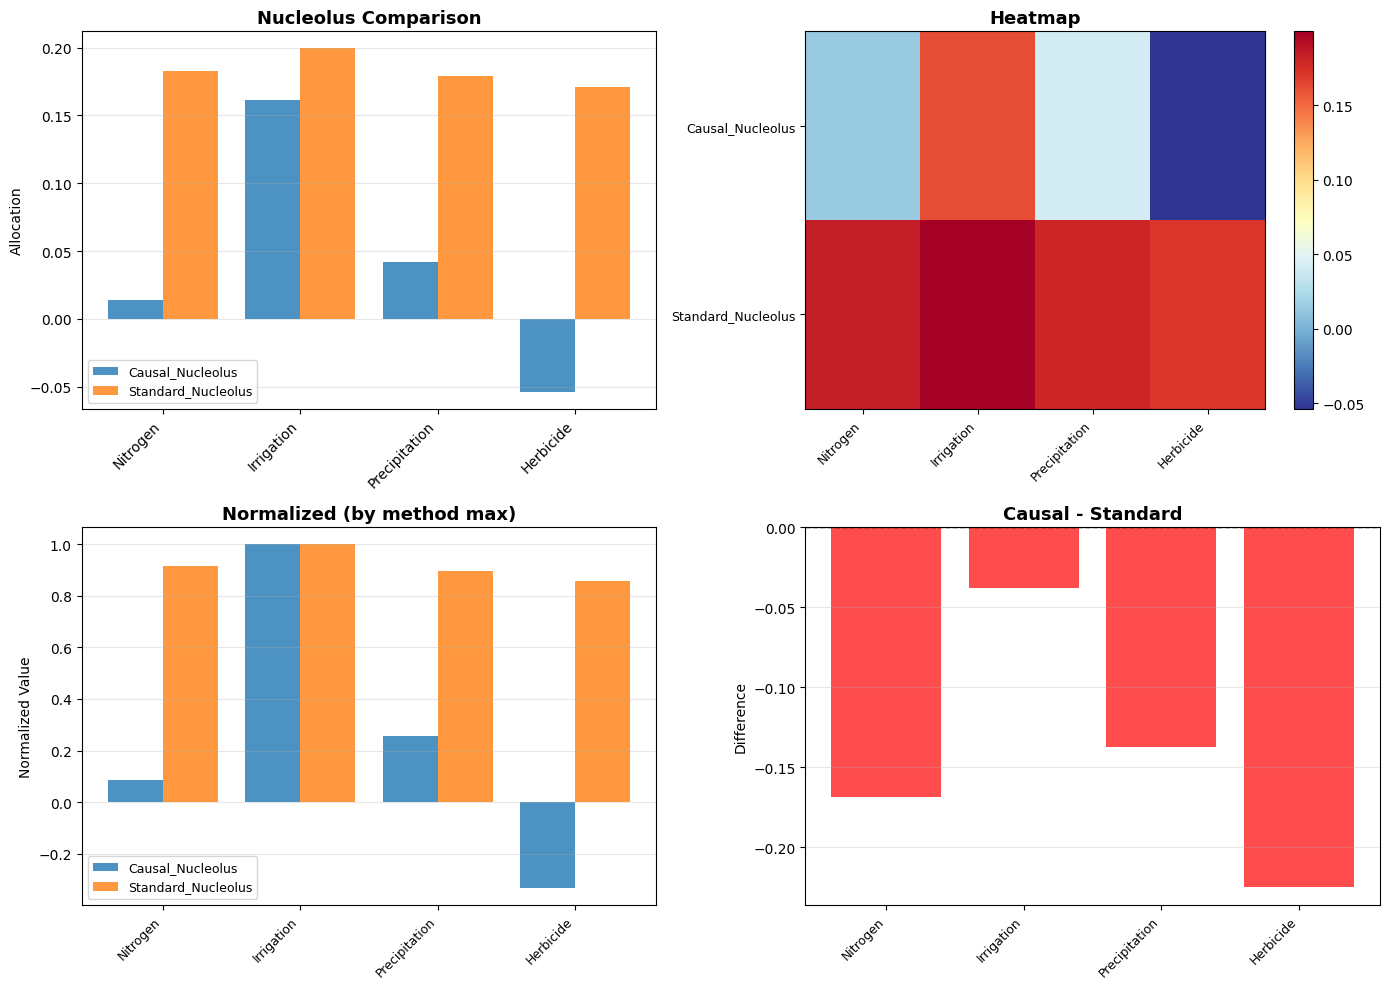

In [7]:
"""
CAUSAL NUCLEOLUS on yield_preprocessed.npz

Extends the Nucleolus to incorporate causal structure:
1. Causal value function: v(S) uses interventional distributions P(X_{-S} | do(X_S))
2. Uses ensemble of DAGs + linear SEMs (same as Causal SHAP / Least Core / Gately)
3. Optional gamma-weighting: utilities scaled by total causal effects W_i
4. Monte Carlo approximation of coalitions for scalability

Standard Nucleolus:
    Lexicographically minimizes the sorted vector of coalition excesses:
        e(S) = v(S) - sum_{i in S} x_i
    subject to efficiency: sum_i x_i = v(N)

Causal version:
    - v(S) defined via interventions do(X_S)
    - v(N) used as efficiency constraint
    - Optional gamma weighting over coalitions

Saves: causal_nucleolus_results.csv, nucleolus_comparison.png
"""

import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set
warnings.filterwarnings("ignore")

import cvxpy as cp
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB=False

from causallearn.search.ConstraintBased.PC import pc

logger = logging.getLogger(__name__)


CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'M_RESAMPLES': 48,         # samples for interventional value v(S)
    'N_DAGS': 3,               # DAGs sampled from CPDAG
    'MC_ITERATIONS': 400,      # coalitions per instance for Monte Carlo nucleolus
    'RANDOM_SEED': 42,
    'K_INSTANCES': 10,         # test instances for global averaging
    'EPSILON': 0.01,           # slack in nucleolus solver
    'USE_GAMMA_WEIGHTS': True, # weight v(S) by causal gamma_i
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


def powerset(iterable):
    from itertools import chain, combinations
    items = list(iterable)
    return chain.from_iterable(combinations(items, r) for r in range(len(items) + 1))


class CausalStructure:
    """PC discovery → CPDAG → sample DAGs."""
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed")
        return self

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """Sample DAGs by orienting undirected edges; ensure acyclicity."""
        dags = []
        names = self.feature_names
        n = len(names)

        undirected = []
        for i in range(n):
            for j in range(i + 1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            # orient undirected edges
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            # last guard
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)

            dags.append(G)

        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags


class LinearMechanisms:
    """SEM fitting for interventional sampling."""
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len(
                    [p for p in self.dag.predecessors(n) if p in remaining]
                ))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """Sample from P(X_{-S} | do(X_S = x_S))."""
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new


class CausalEffects:
    """Compute W_i via path products; average over DAGs."""
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing total causal effects W_i...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = (np.column_stack([X[parents].values, X[u].values])
                         if parents else X[[u]].values)
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                valid = False; break
                            prod *= ed["weight"]
                        if valid:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {
            f: (float(np.mean(vals)) if len(vals) else 0.0)
            for f, vals in totals.items()
        }
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        """Normalized causal importance weights."""
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


def _solve_nucleolus(A, v, epsilon: float = 0.01, **options):
    """
    Lexicographic minimization of coalition excesses via iterative LP
    (same logic as your generic _solve_nucleolus, adapted here).
    """
    n = A.shape[1]  # players
    m = A.shape[0]  # coalitions

    # grand coalition: the row where all memberships sum is max
    grand_coalition_idx = int(np.argmax(np.sum(A, axis=1)))

    active_coalitions = list(range(m))
    active_coalitions.remove(grand_coalition_idx)
    fixed_coalitions = [grand_coalition_idx]
    fixed_values = {}

    x = cp.Variable(n)
    excess = cp.Variable()

    # efficiency: sum_i x_i = v(N)
    constraints = [cp.sum(x) == v[grand_coalition_idx]]

    all_subsidies = np.zeros(m)

    x_values = None

    while active_coalitions:
        constraints_this_round = list(constraints)

        for i in active_coalitions:
            constraints_this_round.append(
                v[i] - cp.sum(cp.multiply(A[i], x)) <= excess + epsilon
            )

        objective = cp.Minimize(excess)
        problem = cp.Problem(objective, constraints_this_round)

        try:
            problem.solve(**options)
        except Exception as e:
            logger.warning(f"Solver error in nucleolus LP: {e}")
            break

        if problem.status not in ["optimal", "optimal_inaccurate"]:
            logger.warning(f"Nucleolus LP not optimal: {problem.status}")
            break

        x_values = x.value
        max_excess = excess.value

        new_fixed = []
        for i in active_coalitions:
            current_excess = v[i] - np.dot(A[i], x_values)
            if abs(current_excess - max_excess) < 1e-5:
                new_fixed.append(i)
                fixed_values[i] = current_excess
                all_subsidies[i] = -current_excess

        if not new_fixed:
            logger.warning("No new coalitions fixed in this round (nucleolus)")
            break

        for i in new_fixed:
            active_coalitions.remove(i)
            fixed_coalitions.append(i)
            constraints.append(
                v[i] - cp.sum(cp.multiply(A[i], x)) == fixed_values[i]
            )

    if x_values is None:
        # fallback: zero allocation
        x_values = np.zeros(n)

    nucleolus_values = x_values
    return nucleolus_values, all_subsidies


class CausalNucleolus:
    """
    Causal Nucleolus.

    Game:
        - Players = features
        - v(S) = E[ max_c f_c(X) | do(X_S = x_S) ]
        - Optionally scaled by average gamma_i over i ∈ S.

    We approximate the nucleolus by:
        - Sampling grand coalition and random coalitions via Monte Carlo
        - Building (A, v) and calling the generic _solve_nucleolus.
    """
    def __init__(self, model, structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = structure
        self.X_train = X_train
        self.y_train = y_train
        self.features = list(X_train.columns)
        self.n = len(self.features)

        print("\nFitting SEMs & sampling DAGs for Causal Nucleolus...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()

        print("Causal Nucleolus ready")

    def causal_value(self, S: Set[int], x: pd.Series, M: int = None) -> float:
        """
        Causal value v(S) for coalition S (indices).
        Value = average max class probability under do(X_S = x_S),
                optionally gamma-weighted.
        """
        if M is None:
            M = CONFIG['M_RESAMPLES']

        if not S:
            return 0.0

        S_names = {self.features[i] for i in S}
        total_samples = max(1, M)
        per_sem = max(1, total_samples // max(1, len(self.sems)))

        samples = []
        for sem in self.sems:
            for _ in range(per_sem):
                x_sample = sem.sample_intervention(S_names, x)
                samples.append([x_sample[f] for f in self.features])

        X_mat = np.array(samples)
        probs = self.model.predict_proba(X_mat)
        value = float(np.max(probs, axis=1).mean())

        if CONFIG['USE_GAMMA_WEIGHTS']:
            gamma_avg = np.mean([self.gamma[self.features[i]] for i in S])
            value *= float(gamma_avg)

        return value

    def sample_coalitions(self, n_samples: int, x: pd.Series):
        """
        Sample random coalitions and their causal values.

        Returns:
            A: (m x n) coalition incidence matrix
            v: length-m utility vector
        """
        coalitions = []
        values = []

        # Always include grand coalition first
        grand = list(range(self.n))
        coalitions.append(grand)
        values.append(self.causal_value(set(grand), x))

        for _ in range(n_samples - 1):
            size = np.random.randint(1, self.n)  # avoid empty
            S = sorted(np.random.choice(self.n, size=size, replace=False).tolist())
            coalitions.append(S)
            values.append(self.causal_value(set(S), x))

        m = len(coalitions)
        A = np.zeros((m, self.n))
        for i, S in enumerate(coalitions):
            A[i, S] = 1.0

        v = np.array(values, dtype=float)
        return A, v

    def compute_nucleolus_instance(self, x: pd.Series,
                                   n_iterations: int = None,
                                   epsilon: float = None) -> Dict:
        """
        Compute causal nucleolus allocation for one instance x.
        """
        if n_iterations is None:
            n_iterations = CONFIG['MC_ITERATIONS']
        if epsilon is None:
            epsilon = CONFIG['EPSILON']

        A, v = self.sample_coalitions(n_iterations, x)

        try:
            values, subsidies = _solve_nucleolus(A, v, epsilon=epsilon)
            status = "Converged"
        except Exception as e:
            logger.error(f"Error in causal nucleolus: {e}")
            values = np.zeros(self.n)
            subsidies = None
            status = "Failed"

        return {
            "values": values,
            "subsidies": subsidies,
            "status": status,
            "v": v,
            "A": A,
        }

    def compute_global(self, X_test: pd.DataFrame, k: int = None) -> pd.Series:
        """Compute global causal nucleolus over k test instances and average."""
        if k is None:
            k = CONFIG['K_INSTANCES']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)

        print(f"\nComputing global Causal Nucleolus over {k} instances...")
        results = []

        for t, i in enumerate(idx, 1):
            if t % 3 == 0:
                print(f"  Instance {t}/{k}")
            res = self.compute_nucleolus_instance(X_test.iloc[i])
            results.append(res["values"])

        avg_values = np.mean(results, axis=0)
        return pd.Series(avg_values, index=self.features,
                         name="Causal_Nucleolus")


def compute_standard_nucleolus(model, X_train, X_test,
                               k=10) -> pd.Series:
    """
    Standard Nucleolus without causal structure.

    Utility uses marginal sampling P(X_{-S}) instead of interventional P(X_{-S} | do(X_S)).
    """
    print("\nComputing Standard Nucleolus (baseline)...")

    def standard_utility(S: Set[int], x: pd.Series, X_bg: pd.DataFrame, M: int = 32) -> float:
        features = list(X_bg.columns)
        total = 0.0
        for _ in range(M):
            x_new = x.copy()
            for j, feat in enumerate(features):
                if j not in S:
                    x_new[feat] = X_bg[feat].sample(1).iloc[0]
            probs = model.predict_proba(pd.DataFrame([x_new], columns=features).values)[0]
            total += float(np.max(probs))
        return total / M

    n = len(X_train.columns)
    players = list(range(n))
    idx = rng.choice(len(X_test), size=min(k, len(X_test)), replace=False)
    results = []

    for t, i in enumerate(idx, 1):
        if t % 3 == 0:
            print(f"  Instance {t}/{len(idx)}")

        x = X_test.iloc[i]
        coalitions = []
        values = []

        # Grand coalition
        grand = players
        coalitions.append(grand)
        values.append(standard_utility(set(grand), x, X_train, M=48))

        # Random coalitions
        for _ in range(CONFIG['MC_ITERATIONS'] - 1):
            size = np.random.randint(1, n)
            S = sorted(np.random.choice(n, size=size, replace=False).tolist())
            coalitions.append(S)
            values.append(standard_utility(set(S), x, X_train, M=32))

        m = len(coalitions)
        A = np.zeros((m, n))
        for idx_c, S in enumerate(coalitions):
            A[idx_c, S] = 1.0

        v = np.array(values, dtype=float)

        try:
            vals, subs = _solve_nucleolus(A, v, epsilon=CONFIG['EPSILON'])
            results.append(vals)
        except Exception as e:
            logger.error(f"Error in standard nucleolus: {e}")
            results.append(np.zeros(n))

    avg_values = np.mean(results, axis=0)
    return pd.Series(avg_values, index=X_train.columns,
                     name="Standard_Nucleolus")


def plot_comparison(df: pd.DataFrame):
    """Compare Causal vs Standard Nucleolus."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    x_pos = np.arange(len(df.index))
    width = 0.8 / len(df.columns)

    # Bar plot
    for i, col in enumerate(df.columns):
        axes[0, 0].bar(x_pos + i * width, df[col], width, label=col, alpha=0.8)
    axes[0, 0].set_xticks(x_pos + width * (len(df.columns) - 1) / 2)
    axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Allocation')
    axes[0, 0].set_title('Nucleolus Comparison', fontweight='bold', fontsize=13)
    axes[0, 0].legend(fontsize=9)
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    im = axes[0, 1].imshow(df.T.values, aspect='auto', cmap='RdYlBu_r')
    axes[0, 1].set_xticks(np.arange(len(df.index)))
    axes[0, 1].set_xticklabels(df.index, rotation=45, ha='right', fontsize=9)
    axes[0, 1].set_yticks(np.arange(len(df.columns)))
    axes[0, 1].set_yticklabels(df.columns, fontsize=9)
    axes[0, 1].set_title('Heatmap', fontweight='bold', fontsize=13)
    plt.colorbar(im, ax=axes[0, 1])

    # Normalized comparison
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(x_pos + i * width, df_norm[col], width, label=col, alpha=0.8)
    axes[1, 0].set_xticks(x_pos + width * (len(df_norm.columns) - 1) / 2)
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right', fontsize=9)
    axes[1, 0].set_ylabel('Normalized Value')
    axes[1, 0].set_title('Normalized (by method max)', fontweight='bold', fontsize=13)
    axes[1, 0].legend(fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Difference Causal - Standard
    if 'Standard_Nucleolus' in df.columns and 'Causal_Nucleolus' in df.columns:
        diff = df['Causal_Nucleolus'] - df['Standard_Nucleolus']
        colors = ['green' if v > 0 else 'red' for v in diff]
        axes[1, 1].bar(x_pos, diff, color=colors, alpha=0.7)
        axes[1, 1].set_xticks(x_pos)
        axes[1, 1].set_xticklabels(df.index, rotation=45, ha='right', fontsize=9)
        axes[1, 1].set_ylabel('Difference')
        axes[1, 1].set_title('Causal - Standard', fontweight='bold', fontsize=13)
        axes[1, 1].axhline(y=0, color='black', linestyle='--', linewidth=1)
        axes[1, 1].grid(axis='y', alpha=0.3)
    else:
        axes[1, 1].text(0.5, 0.5, 'Difference plot\nrequires both methods',
                        ha='center', va='center', transform=axes[1, 1].transAxes)

    fig.tight_layout()
    return fig


def main():
    print("\n" + "=" * 72)
    print("CAUSAL NUCLEOLUS")
    print("=" * 72 + "\n")

    # Load data
    print("Loading NPZ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        print(f"keys: {list(data.keys())}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found.")
        return

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")

    # Scale
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    # Train model
    print("\n" + "=" * 72)
    print("Training model")
    print("=" * 72)
    n_classes = len(np.unique(y_train))

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=100, max_depth=5, learning_rate=0.1,
            random_state=CONFIG['RANDOM_SEED'], verbosity=0,
            objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(
            n_estimators=100, max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest")

    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test, y_pred):.4f}  "
          f"MacroF1={f1_score(y_test, y_pred, average='macro'): .4f}")

    # Causal discovery
    print("\n" + "=" * 72)
    print("Causal Discovery (PC)")
    print("=" * 72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)

    # Causal Nucleolus
    print("\n" + "=" * 72)
    print("Computing Causal Nucleolus")
    print("=" * 72)
    cnuc = CausalNucleolus(model, cs, Xtr, y_train)

    print("\nCausal effects (gamma weights):")
    for f in Xtr.columns:
        print(f"  {f:15s}  γ={cnuc.gamma[f]:.5f}")

    causal_nuc = cnuc.compute_global(Xte, k=CONFIG['K_INSTANCES'])

    # Baseline
    standard_nuc = compute_standard_nucleolus(model, Xtr, Xte,
                                              k=CONFIG['K_INSTANCES'])

    # Results
    print("\n" + "=" * 72)
    print("Results")
    print("=" * 72)
    df = pd.DataFrame({
        "Causal_Nucleolus":   causal_nuc,
        "Standard_Nucleolus": standard_nuc,
    })

    df.to_csv("causal_nucleolus_results.csv", index=True)
    print(df.round(6).to_string())
    print("\nSaved: causal_nucleolus_results.csv")

    fig = plot_comparison(df)
    fig.savefig("nucleolus_comparison.png", dpi=150, bbox_inches='tight')
    print("Saved: nucleolus_comparison.png")

    try:
        plt.show()
    except Exception:
        pass


if __name__ == "__main__":
    main()